# Bayes Classifier with Custom Densities

I extended the Gaussian Bayes classifier to accept kernel density estimates and custom likelihood functions. The notebook checks both interfaces and retains the Gaussian model tests.

### Test Bench

In [6]:
%load_ext autoreload
%autoreload 2
# No need to restart the notebook upon change thanks to autoreload
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis

from BayesClassifier import BayesClassifier
from KDEstimator import KDEstimator

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### Generate Synthetic Data

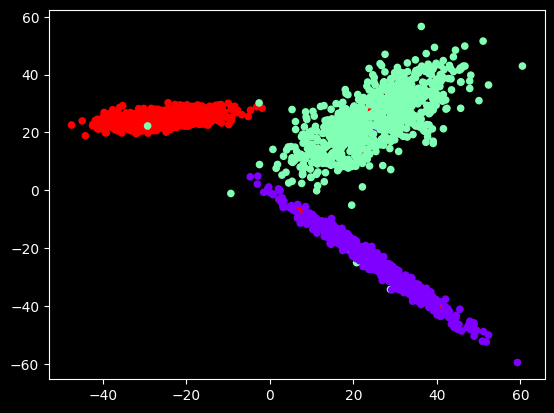

In [7]:
# Generate synthetic data
X, y = make_classification(n_samples=3000, n_features=2, n_classes=3, n_clusters_per_class=1, 
                           random_state=0,  n_informative=2, n_redundant=0, class_sep=2.5, scale=10)
x_train, x_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# Plot the data
plt.style.use('dark_background')
plt.scatter(x_train[:, 0], x_train[:, 1], c=y_train, s=20, cmap='rainbow')
plt.show()

### 1) Testing KDE

In [8]:
# This is a weak test but the KDE notebook took care of stronger ones
kde = KDEstimator(bump='Gauss', bandwidth='Scott')
kde_clf = BayesClassifier(mode='KDE', kde_config=kde)
kde_clf.fit(x_train, y_train)

# Ensure it's equivalent to using QDA
normal_clf = BayesClassifier(mode='QDA')
normal_clf.fit(x_train, y_train)

# Number of points is large KDE estimate should be just like real assumption (accurate)
np.allclose(kde_clf.predict(x_val), normal_clf.predict(x_val))

True

### 2) Testing Custom Density

In [9]:
from numpy.linalg import det, inv

# Define the density which takes x and the parameters
def N(x, params):
    μ, Σ = params['μ'], params['Σ']
    π, N= np.pi, len(μ)
    P = np.exp(-0.5 * ( (x - μ).T @ inv(Σ) @  (x- μ))) / np.sqrt((2*π)**N * det(Σ))
    return P

# Define a function that estimates the paramers of the density
def estimate_params(x_data):
    μ = np.mean(x_data, axis=0)
    Σ = np.cov(x_data, rowvar=False)
    return {'μ': μ, 'Σ':Σ}

# Consider passing a custom density which is normal distribution in this case
# Normal usecace will certainly be an external distribution but this is just to test
custom_clf = BayesClassifier(mode='Custom', density=N, estimate_params=estimate_params)
custom_clf.fit(x_train, y_train)

# Ensure it's equivalent to using QDA
normal_clf = BayesClassifier(mode='QDA')
normal_clf.fit(x_train, y_train)

# Assert equivalence
np.allclose(custom_clf.predict_proba(x_val), normal_clf.predict_proba(x_val))

True

### 3) Kernel Density & Custom Density Combo Test

In [10]:
def P(x, params):
    kde = params['kde']
    return kde.transform(x)

# define a function that estimates the paramers of the density
def estimate_params(x_data):
    kde = KDEstimator(bandwidth='Scott', bump='Gauss')
    kde.fit(x_data)
    return {'kde': kde}

custom_clf = BayesClassifier(mode='Custom', density=P, estimate_params=estimate_params)
custom_clf.fit(x_train, y_train)

np.all(kde_clf.predict(x_val) == custom_clf.predict(x_val))

np.True_

### 4) Testing QDA

1.1 Fits without errors

In [11]:
my_classifier = BayesClassifier(mode='QDA')
my_classifier.fit(x_train, y_train)

1.2 Test basic properties of parameters

In [12]:
assert len(my_classifier.means) == len(my_classifier.labels)
assert my_classifier.means[0].shape == (2,)
assert len(my_classifier.covs) == len(my_classifier.labels)
assert my_classifier.covs[0].shape == (2,2)
assert len(my_classifier.priors) == len(my_classifier.labels)
assert my_classifier.priors.sum() == 1

1.3 Test that parameters are set correctly

In [13]:
# compare with scikit parameters
clf = QuadraticDiscriminantAnalysis(store_covariance=True)
clf.fit(x_train, y_train)
assert np.allclose(my_classifier.means, clf.means_)
assert np.allclose(my_classifier.covs, clf.covariance_)
assert np.allclose(my_classifier.priors, clf.priors_)

1.5 Basic test for `predict_proba_x` 

In [14]:
y_pred = my_classifier.predict_proba_x(np.random.rand(2))
assert y_pred.shape == (3,)
assert np.allclose(np.sum(y_pred), 1)

1.6 It follows that `predict_proba` is implemented correctly

In [15]:
assert np.allclose(my_classifier.predict_proba(x_val), clf.predict_proba(x_val))

1.7 Test `predict`

In [16]:
y_pred = my_classifier.predict(x_val)
assert y_pred.shape == y_val.shape
assert np.allclose(y_pred, clf.predict(x_val))

1.8 Test `accuracy`

In [17]:
assert np.allclose(my_classifier.score(x_val, y_val), clf.score(x_val, y_val))

### 5) Testing LDA

In [18]:
my_classifier = BayesClassifier(mode='LDA')
my_classifier.fit(x_train, y_train)

2.1 Test basic properties of parameters

In [19]:
assert len(my_classifier.means) == len(my_classifier.labels)
assert not hasattr(my_classifier, 'covs'), "LDA should not have covs attribute"
assert len(my_classifier.priors) == len(my_classifier.labels)
assert my_classifier.priors.sum() == 1

2.2 Test parameter values

In [20]:
clf = LinearDiscriminantAnalysis(solver='eigen', store_covariance=True)
clf.fit(x_train, y_train)
assert np.allclose(my_classifier.weighted_cov, clf.covariance_)
assert np.allclose(my_classifier.means, clf.means_)
assert np.allclose(my_classifier.priors, clf.priors_)

2.3 Basic test for `predict_proba_x` 

In [21]:
y_pred = my_classifier.predict_proba_x(np.random.rand(2,))
assert y_pred.shape == (3,)
assert np.allclose(np.sum(y_pred), 1)

2.4 End-to-end tests

In [22]:
assert np.allclose(my_classifier.predict_proba(x_val), clf.predict_proba(x_val))

y_pred = my_classifier.predict(x_val)
assert y_pred.shape == y_val.shape
assert np.allclose(y_pred, clf.predict(x_val))

### 6) Testing Gaussian Naive Bayes

In [23]:
my_classifier = BayesClassifier(mode='GNB')
my_classifier.fit(x_train, y_train)

3.1 Test basic properties of parameters

In [24]:
assert len(my_classifier.means) == len(my_classifier.labels)
assert len(my_classifier.covs) == len(my_classifier.labels)
assert len(my_classifier.priors) == len(my_classifier.labels)
assert my_classifier.priors.sum() == 1

3.2 Test parameter values

In [25]:
clf = GaussianNB()
clf.fit(x_train, y_train)
assert np.allclose(my_classifier.priors, clf.class_prior_)
assert np.allclose(my_classifier.means, clf.theta_)
# loop on each row of clf.var_ and ensure the computed variances for a class are the diagonal of corresponding covariance matrix
for i in range(clf.var_.shape[0]): assert np.allclose(my_classifier.covs[i], np.diag(clf.var_[i]))

3.3 End-to-end test

In [26]:
assert np.allclose(my_classifier.predict_proba(x_val), clf.predict_proba(x_val))

y_pred = my_classifier.predict(x_val)
assert y_pred.shape == y_val.shape
assert np.allclose(y_pred, clf.predict(x_val))